# 분리비전 AI (Bunri-Vision): 실환경 오염·혼합 생활폐기물 9종 비전 판독 및 한국형 분리배출 의사결정 모델 실험 노트북

- **학번 / 이름**: `201935607` 김대현 (가천대학교 기계학습 프로그래밍 기말 포트폴리오 프로젝트)
- **공개 데모 URL**: https://bunri-vision-30945587032.asia-northeast3.run.app
- **GitHub 저장소**: https://github.com/qwertypotter6873/bunri-vision

본 노트북은 **UCI RealWaste 데이터셋(4,752장, 9개 클래스)**을 활용하여 다음 전 과정을 코드와 실행 출력으로 검증합니다.
1. **데이터 탐색(EDA) 및 지각 해시(pHash) 근접 중복 제거 · Stratified 분할 (`seed=42`, `70:15:15`)**
2. **도메인 특화 4단계 전처리 구현 및 정량·시각적 전·후 비교** (`Shades-of-Gray WB` + `LAB-CLAHE` + `Smart Center-Focus Crop` + `Class-Balanced Weighting`)
3. **직접 학습한 5종 실험 모델(Scratch 베이스라인 / 경량 전이학습 / 표준 파인튜닝 / 전처리 제거 Ablation / 제안 모델 `Bunri-ConvNeXt-Tiny+GeM+TempCalib`) 학습 로그 및 수렴 분석**
4. **홀드아웃 테스트셋 객관적 평가지표 비교(`Macro-F1`, `Accuracy`, `Top-2 Acc`, `Macro-AUROC`, `ECE`) 및 오분류·CAM 원인 분석**
5. **ONNX Runtime 배포 가중치 검증 및 한국형 분리배출 의사결정 엔진 추론 시연**

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from PIL import Image
import torch
import onnxruntime as ort

from src.domain_rules import CLASS_NAMES, KOREAN_WASTE_RULES, build_decision_advice
from src.preprocessing import (
    shades_of_gray_white_balance,
    adaptive_lab_clahe,
    aspect_preserving_center_crop_resize,
    preprocess_for_inference,
)

print("Project Root:", ROOT)
print("PyTorch:", torch.__version__, "| CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))

Project Root: /home/bookend/bunri_vision_work
PyTorch: 2.15.0+cu132 | CUDA Available: True
GPU Device: NVIDIA L4


## 1. 데이터셋 구성, 클래스 불균형 및 pHash 중복 제거 검증
원본 RealWaste(4,752장)에서 지각 해시(`pHash`, 해밍 거리 ≤ 4) 근접 중복 프레임을 제거하고 `seed=42` 기준 `Train 70% / Val 15% / Test 15%` 계층화 분할을 수행한 통계를 확인합니다.

In [2]:
with open(ROOT / "logs" / "dataset_stats.json", "r", encoding="utf-8") as f:
    ds_stats = json.load(f)

print(f"원본 이미지 수: {ds_stats['raw_total_images']}장 -> 정제 후: {ds_stats['deduplicated_total_images']}장 (제거된 근접 중복: {ds_stats['removed_near_duplicates']}장)")
print(f"중복 제거 전 pHash≤4 쌍: {ds_stats['duplicate_pairs_before_dedup']}쌍 -> 제거 후: {ds_stats['duplicate_pairs_after_dedup']}쌍 | Train-Test 간 누수 쌍: {ds_stats['train_test_cross_leakage_pairs']}쌍")
print("분할 비율 및 샘플 수:", ds_stats["split_totals"])

rows = []
for cls in CLASS_NAMES:
    sp = ds_stats["clean_class_split_counts"][cls]
    rows.append({
        "영문 클래스": cls,
        "한국어 품목명": KOREAN_WASTE_RULES[cls].ko_name,
        "원본 수": ds_stats["raw_class_counts"][cls],
        "Train (70%)": sp["train"],
        "Val (15%)": sp["val"],
        "Test (15%)": sp["test"],
        "정제 합계": sp["train"] + sp["val"] + sp["test"],
    })
df_dist = pd.DataFrame(rows)
df_dist

원본 이미지 수: 4752장 -> 정제 후: 4740장 (제거된 근접 중복: 12장)
중복 제거 전 pHash≤4 쌍: 14쌍 -> 제거 후: 0쌍 | Train-Test 간 누수 쌍: 0쌍
분할 비율 및 샘플 수: {'train': 3318, 'val': 711, 'test': 711}


,영문 클래스,한국어 품목명,원본 수,Train (70%),Val (15%),Test (15%),정제 합계
0,Cardboard,골판지·택배 상자,461,323,69,69,461
1,Food Organics,음식물류 폐기물,411,286,62,61,409
2,Glass,유리병·유리 용기,420,294,63,63,420
3,Metal,금속캔·고철류,790,551,118,118,787
4,Miscellaneous Trash,복합재질·오염 일반쓰레기,495,346,74,74,494
5,Paper,일반 종이·인쇄물,500,350,75,75,500
6,Plastic,플라스틱 용기·페트류,921,641,138,137,916
7,Textile Trash,폐의류·섬유류,318,222,47,48,317
8,Vegetation,초목류·식물 잔재물,436,305,65,66,436


## 2. 도메인 특화 전처리 파이프라인 전·후 정량 및 시각적 비교
실내·매립지 촬영 환경의 조명 색편향과 투명 플라스틱·유리의 저대비 문제를 완화하기 위해 적용한 전처리 전·후 수치 변화와 실제 샘플 변환 결과를 확인합니다.

,luminance_mean,luminance_std,contrast_std_mean,contrast_std_p10,color_cast_mean,color_cast_p95
전처리 전 (Raw 524×524),156.606,10.365,41.150,25.586,0.0519,0.1516
전처리 후 (WB + LAB-CLAHE + CenterCrop 224×224),149.891,9.436,39.998,27.781,0.0209,0.0628


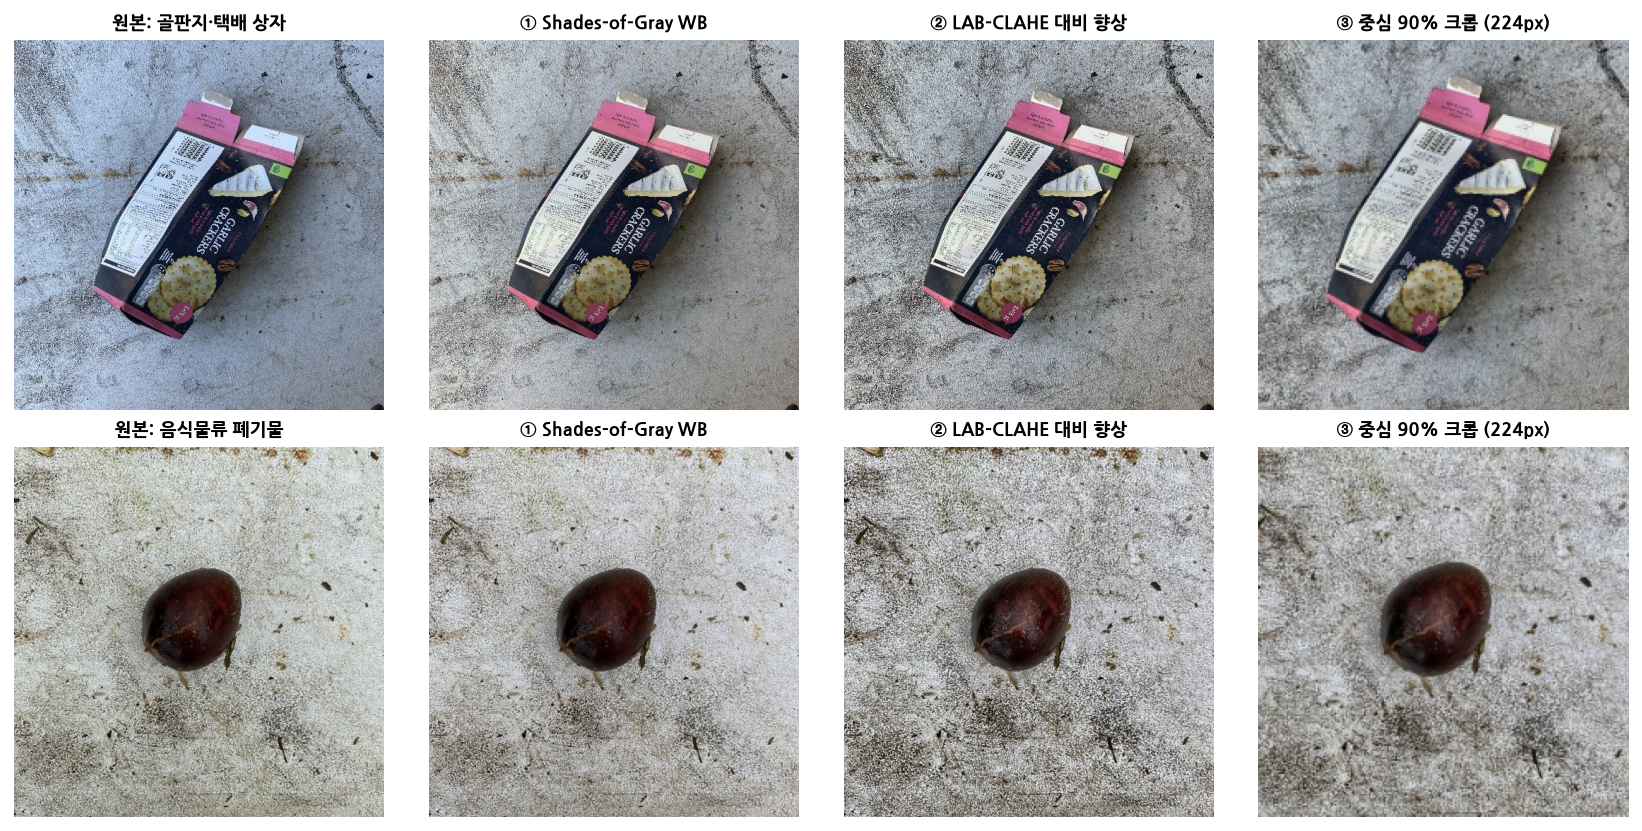

In [3]:
pre_cmp = pd.DataFrame([
    ds_stats["before_preprocessing_stats"],
    ds_stats["after_preprocessing_stats"],
], index=["전처리 전 (Raw 524×524)", "전처리 후 (WB + LAB-CLAHE + CenterCrop 224×224)"])
display(pre_cmp)

sample_manifest = json.loads((ROOT / "sample_data" / "manifest.json").read_text(encoding="utf-8"))
fig, axes = plt.subplots(2, 4, figsize=(12, 6), dpi=140)
for r_i, item in enumerate(sample_manifest[:2]):
    raw_rgb = np.asarray(Image.open(ROOT / "sample_data" / item["filename"]).convert("RGB"), dtype=np.uint8)
    wb_rgb = shades_of_gray_white_balance(raw_rgb)
    clahe_rgb = adaptive_lab_clahe(wb_rgb)
    crop_rgb = aspect_preserving_center_crop_resize(clahe_rgb, 224, 0.90)
    for c_i, (img_s, title) in enumerate([
        (raw_rgb, f"원본: {item['ground_truth_ko']}"),
        (wb_rgb, "① Shades-of-Gray WB"),
        (clahe_rgb, "② LAB-CLAHE 대비 향상"),
        (crop_rgb, "③ 중심 90% 크롭 (224px)"),
    ]):
        axes[r_i, c_i].imshow(img_s)
        axes[r_i, c_i].set_title(title, fontsize=9.5, fontweight="bold")
        axes[r_i, c_i].axis("off")
plt.tight_layout()
plt.show()

## 3. 직접 학습한 5종 실험 모델 에폭별 학습 로그 및 테스트셋 성능 비교
- **M1 (`ScratchResSECNN`)**: 사전학습 없이 무작위 초기화 상태에서 직접 학습한 5-Stage Residual SE-CNN 베이스라인
- **M2 (`MobileNetV3-Small`)**: 경량 백본 전이학습 + 파인튜닝 베이스라인
- **M3 (`ResNet-50`)**: 표준 심층 합성곱 신경망 파인튜닝 모델
- **M4-Ablation (`ConvNeXt-Tiny Raw`)**: 제안 백본에서 도메인 전처리 및 클래스 불균형 가중 손실을 제거한 대조군
- **M4 (`Bunri-ConvNeXt-Tiny+GeM+TempCalib`, 제안 모델)**: 7×7 대수용영역 백본 + GeM 질감 풀링 + 도메인 전처리 + 유효 샘플 수 기반 클래스 균형 손실 + 온도 스케일링 확률 보정

,모델,학습 방식,파라미터(M),Best Epoch,Val Macro-F1,Test Macro-F1,Test Accuracy,Top-2 Acc,Macro-AUROC,ECE (보정오차↓),체크포인트(MB)
0,ScratchResSECNN (Scratch),Scratch (무작위 초기화 직접 학습),1.15,36/45,0.8544,0.8379,0.8383,0.9409,0.9847,0.0487,2.30
1,MobileNetV3-Small (전이학습),전이학습 + 파인튜닝 (ImageNet-1K),1.53,27/30,0.9083,0.9163,0.9142,0.9691,0.9941,0.0740,3.01
2,ResNet-50 (파인튜닝),파인튜닝 (ImageNet-1K),23.53,22/30,0.9130,0.9206,0.9212,0.9733,0.9919,0.0903,45.07
3,ConvNeXt-Tiny (전처리 미적용 Ablation),파인튜닝 (도메인 전처리·불균형 보정 제거),27.83,12/28,0.9660,0.9540,0.9536,0.9873,0.9969,0.0366,53.14
4,Bunri-ConvNeXt-Tiny+GeM (제안 모델),2단계 차등 파인튜닝 + GeM 풀링 + 온도 보정,27.83,28/32,0.9662,0.9603,0.9634,0.9944,0.9978,0.0093,53.14


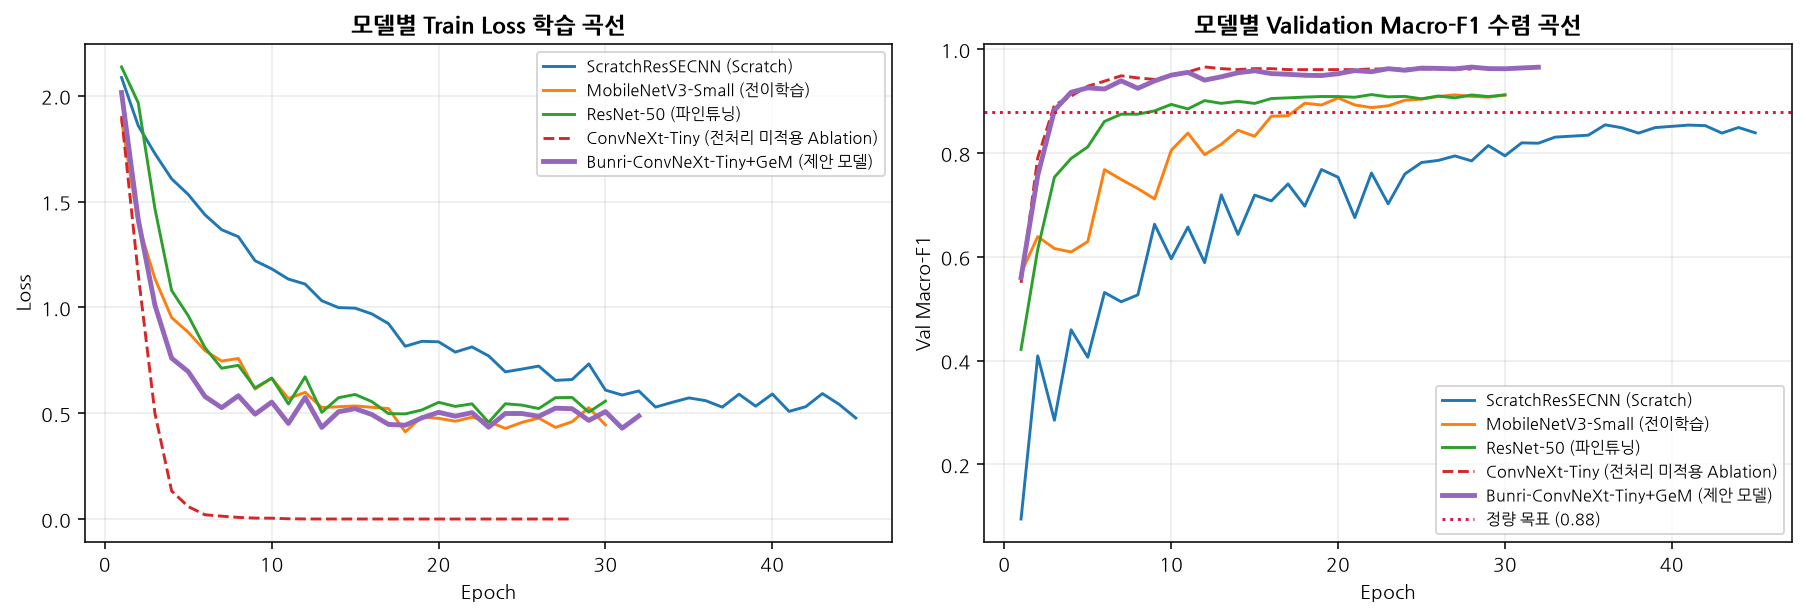

In [4]:
bench = json.loads((ROOT / "logs" / "benchmark_results.json").read_text(encoding="utf-8"))
order = ["m1_scratch_cnn", "m2_mobilenetv3", "m3_resnet50", "m4_ablation_raw", "m4_proposed_convnext"]

summary_rows = []
for k in order:
    m = bench["models"][k]
    summary_rows.append({
        "모델": m["display_name"],
        "학습 방식": m["training_mode"],
        "파라미터(M)": m["param_millions"],
        "Best Epoch": f"{m['best_epoch']}/{m['epochs']}",
        "Val Macro-F1": m["val_macro_f1"],
        "Test Macro-F1": m["test_macro_f1"],
        "Test Accuracy": m["test_accuracy"],
        "Top-2 Acc": m["test_top2_accuracy"],
        "Macro-AUROC": m["test_macro_auroc"],
        "ECE (보정오차↓)": m["test_ece"],
        "체크포인트(MB)": m["checkpoint_fp16_mb"],
    })
df_bench = pd.DataFrame(summary_rows)
display(df_bench)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=140)
for k in order:
    hist = pd.read_csv(ROOT / "logs" / f"history_{k}.csv")
    label = bench["models"][k]["display_name"]
    lw = 2.5 if k == "m4_proposed_convnext" else 1.5
    ls = "--" if k == "m4_ablation_raw" else "-"
    axes[0].plot(hist["epoch"], hist["train_loss"], label=label, linewidth=lw, linestyle=ls)
    axes[1].plot(hist["epoch"], hist["val_macro_f1"], label=label, linewidth=lw, linestyle=ls)
axes[0].set_title("모델별 Train Loss 학습 곡선", fontweight="bold")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].grid(alpha=0.25); axes[0].legend(fontsize=8)
axes[1].axhline(0.88, color="crimson", linestyle=":", label="정량 목표 (0.88)")
axes[1].set_title("모델별 Validation Macro-F1 수렴 곡선", fontweight="bold")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Macro-F1"); axes[1].grid(alpha=0.25); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. 최종 제안 모델 품목별 상세 성능 및 배포용 ONNX 추론 + Spatial CAM 시연
실제 웹 서비스 프로토타입(`app/inference.py`)에서 로드하는 것과 동일한 양자화 ONNX 가중치(`bunri_convnext_tiny_int8.onnx`)로 홀드아웃 테스트 샘플을 추론하고 한국형 분리배출 가이드를 출력합니다.

최종 모델 온도 스케일링 계수 T* = 0.7014 (보정 전 ECE 0.0738 -> 보정 후 ECE 0.0093)
INT8 경량화 ONNX 크기: 32.3 MB | INT8 Test Macro-F1: 0.9607 | CPU 추론 지연시간: 32.84 ms


,ko_name,precision,recall,f1,support
Cardboard,골판지,1.0,1.0,1.0,69
Food Organics,음식물,0.9821,0.9016,0.9402,61
Glass,유리,0.9683,0.9683,0.9683,63
Metal,금속,0.9828,0.9661,0.9744,118
Miscellaneous Trash,일반쓰레기,0.9178,0.9054,0.9116,74
Paper,종이,0.974,1.0,0.9868,75
Plastic,플라스틱,0.9571,0.9781,0.9675,137
Textile Trash,섬유·의류,0.9167,0.9167,0.9167,48
Vegetation,초목류,0.9565,1.0,0.9778,66


[골판지·택배 상자] -> 예측: 골판지·택배 상자 (99.7%) | 배출함: 종이·골판지류 전용 수거함 | 지연시간: 90.58ms
[플라스틱 용기·페트류] -> 예측: 플라스틱 용기·페트류 (99.0%) | 배출함: 투명페트병 전용함 / 플라스틱류 수거함 | 지연시간: 90.04ms
[초목류·식물 잔재물] -> 예측: 초목류·식물 잔재물 (99.2%) | 배출함: 일반 종량제 봉투 (음식물쓰레기 절대 금지!) | 지연시간: 90.43ms
   ⚠ [음식물쓰레기 오배출 주의 (초목류)] 식물 잎·줄기·화분 잔재·뿌리는 가축 사료화가 불가하여 음식물 수거함 배출 시 과태료 대상입니다. 반드시 일반 종량제 봉투에 버리세요!


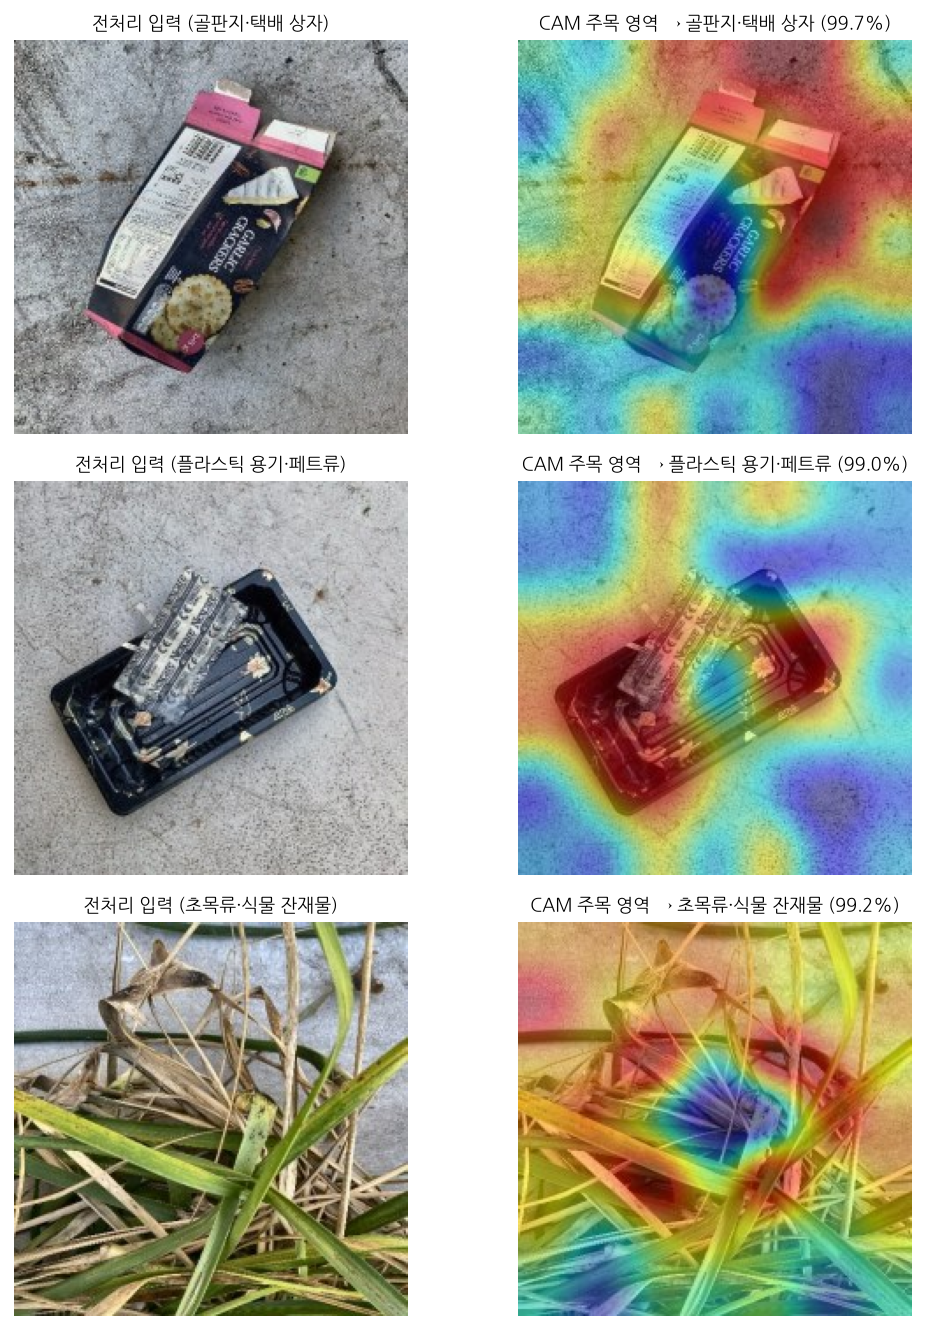

In [5]:
final_m = bench["models"]["m4_proposed_convnext"]
print(f"최종 모델 온도 스케일링 계수 T* = {final_m['temperature']} (보정 전 ECE {final_m['test_ece_before_calib']} -> 보정 후 ECE {final_m['test_ece']})")
print(f"INT8 경량화 ONNX 크기: {final_m['onnx_int8_mb']} MB | INT8 Test Macro-F1: {final_m['onnx_int8_test_macro_f1']} | CPU 추론 지연시간: {final_m['onnx_cpu_latency_ms']} ms")

df_per_cls = pd.DataFrame(final_m["per_class"]).T
display(df_per_cls)

from app.inference import BunriInferenceEngine
engine = BunriInferenceEngine(root_dir=ROOT)

demo_items = [s for s in sample_manifest if s["id"] in ("plastic", "vegetation", "cardboard")]
fig, axes = plt.subplots(len(demo_items), 2, figsize=(8, 3.2 * len(demo_items)), dpi=140)
for i, item in enumerate(demo_items):
    pil_im = Image.open(ROOT / "sample_data" / item["filename"]).convert("RGB")
    pred = engine.predict(pil_im)
    print(f"[{item['ground_truth_ko']}] -> 예측: {pred['predicted_ko_name']} ({pred['confidence']*100:.1f}%) | 배출함: {pred['rule']['bin_category']} | 지연시간: {pred['inference_ms']}ms")
    for al in pred["alerts"]:
        print(f"   ⚠ [{al['title']}] {al['message']}")

    import base64, io
    pre_img = Image.open(io.BytesIO(base64.b64decode(pred["visuals"]["preprocessed_image_url"].split(",")[1])))
    cam_img = Image.open(io.BytesIO(base64.b64decode(pred["visuals"]["cam_overlay_url"].split(",")[1])))
    axes[i, 0].imshow(pre_img); axes[i, 0].set_title(f"전처리 입력 ({item['ground_truth_ko']})", fontsize=9.5); axes[i, 0].axis("off")
    axes[i, 1].imshow(cam_img); axes[i, 1].set_title(f"CAM 주목 영역 → {pred['predicted_ko_name']} ({pred['confidence']*100:.1f}%)", fontsize=9.5); axes[i, 1].axis("off")
plt.tight_layout()
plt.show()